<a href="https://colab.research.google.com/github/Euripedes357/GMSF/blob/main/C%C3%B3pia_de_Cats_and_Dogs_Analise_Exploratoria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path
from collections import Counter
import zipfile
import pandas as pd
from IPython.display import display

# Pasta que você criou no Google Drive
pasta = (
    Path("/content/drive/MyDrive")
    / "MODELAGEM DE DADOS  E DEEP LEARNING by Euripedes Gomes"
)

# Procura o arquivo dentro dessa pasta e de suas subpastas
encontrados = list(pasta.rglob("kagglecatsanddogs_5340.zip"))

if not encontrados:
    raise FileNotFoundError(
        "ZIP não encontrado. Confira o nome da pasta no Drive, "
        "inclusive os espaços, e ajuste a variável 'pasta'."
    )

if len(encontrados) > 1:
    raise ValueError(
        "Há mais de um ZIP com esse nome. Caminhos encontrados:\n"
        + "\n".join(str(p) for p in encontrados)
    )

arquivo_zip = encontrados[0]
print("Arquivo encontrado:", arquivo_zip.name)

extensoes_imagem = {
    ".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp", ".tif", ".tiff"
}

with zipfile.ZipFile(arquivo_zip) as zip_ref:
    arquivos = [
        item for item in zip_ref.infolist()
        if not item.is_dir()
    ]

    imagens = [
        item for item in arquivos
        if Path(item.filename).suffix.lower() in extensoes_imagem
    ]

    contagem_pastas = Counter(
        str(Path(item.filename).parent) for item in imagens
    )

    tabela = pd.DataFrame(
        contagem_pastas.items(),
        columns=["Pasta dentro do ZIP", "Quantidade de imagens"]
    ).sort_values("Pasta dentro do ZIP")

    print(f"\nTotal de arquivos: {len(arquivos):,}")
    print(f"Arquivos com extensão de imagem: {len(imagens):,}")
    print(f"Outros arquivos: {len(arquivos) - len(imagens):,}")

    tamanho_total = sum(item.file_size for item in arquivos)
    print(f"Tamanho descompactado: {tamanho_total / 1024**3:.2f} GiB")

    print("\nIMAGENS POR PASTA")
    display(tabela.reset_index(drop=True))

    print("\nPRIMEIROS 10 NOMES DE IMAGENS")
    for item in imagens[:10]:
        print(item.filename)

Arquivo encontrado: kagglecatsanddogs_5340.zip

Total de arquivos: 25,004
Arquivos com extensão de imagem: 25,000
Outros arquivos: 4
Tamanho descompactado: 0.81 GiB

IMAGENS POR PASTA


,Pasta dentro do ZIP,Quantidade de imagens
0,PetImages/Cat,12500
1,PetImages/Dog,12500



PRIMEIROS 10 NOMES DE IMAGENS
PetImages/Cat/0.jpg
PetImages/Cat/1.jpg
PetImages/Cat/10.jpg
PetImages/Cat/100.jpg
PetImages/Cat/1000.jpg
PetImages/Cat/10000.jpg
PetImages/Cat/10001.jpg
PetImages/Cat/10002.jpg
PetImages/Cat/10003.jpg
PetImages/Cat/10004.jpg


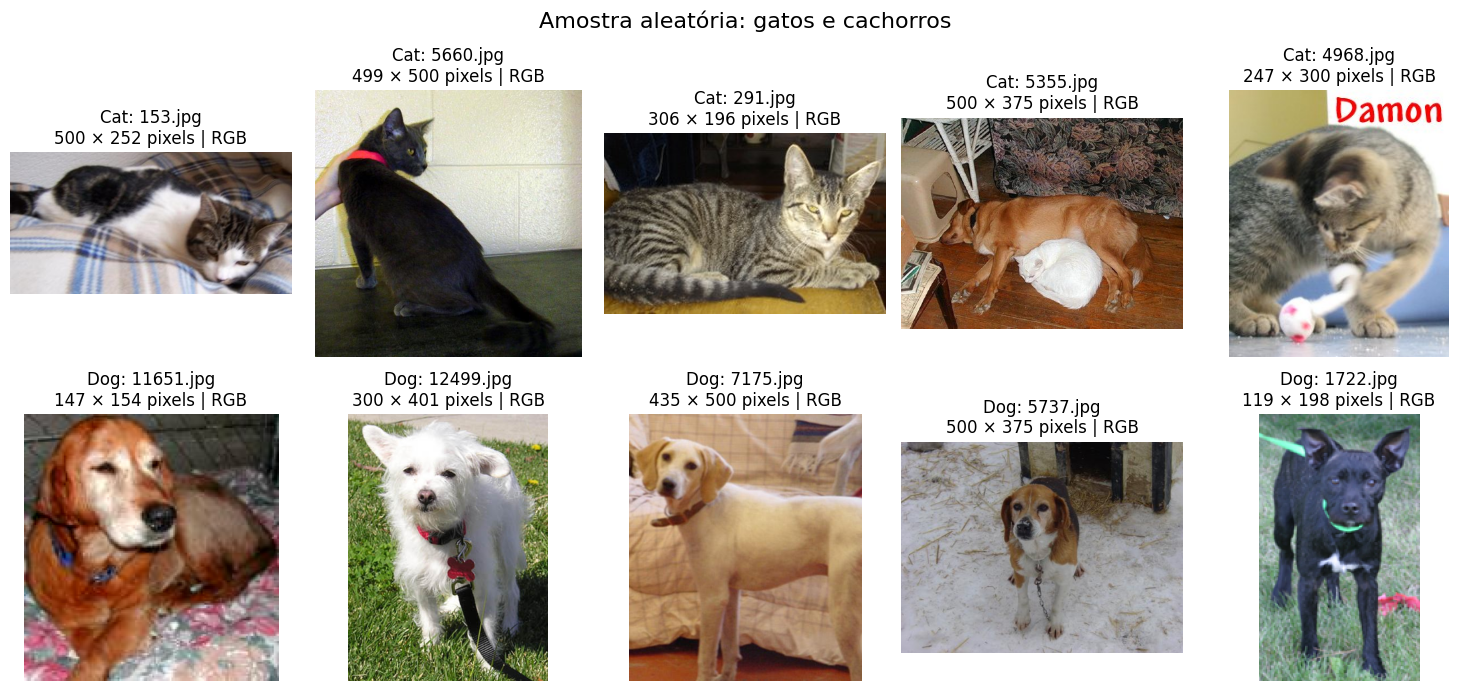

Falhas encontradas durante a seleção: 0


In [4]:
import random
import zipfile
from pathlib import PurePosixPath
from PIL import Image
import matplotlib.pyplot as plt

# Usa o caminho arquivo_zip encontrado na célula anterior.
sorteio = random.Random(42)

fig, eixos = plt.subplots(2, 5, figsize=(15, 7))
falhas = []

with zipfile.ZipFile(arquivo_zip) as zip_ref:
    for linha, classe in enumerate(["Cat", "Dog"]):

        # Lista as imagens da classe.
        candidatos = [
            nome for nome in zip_ref.namelist()
            if PurePosixPath(nome).parent.as_posix()
            == f"PetImages/{classe}"
            and PurePosixPath(nome).suffix.lower()
            in {".jpg", ".jpeg", ".png"}
        ]

        sorteio.shuffle(candidatos)
        coluna = 0

        for nome in candidatos:
            if coluna == 5:
                break

            try:
                with zip_ref.open(nome) as arquivo:
                    with Image.open(arquivo) as imagem:
                        imagem.load()  # Testa a decodificação desta imagem.
                        largura, altura = imagem.size
                        modo = imagem.mode
                        visualizacao = imagem.convert("RGB")

                ax = eixos[linha, coluna]
                ax.imshow(visualizacao)
                ax.set_title(
                    f"{classe}: {PurePosixPath(nome).name}\n"
                    f"{largura} × {altura} pixels | {modo}"
                )
                ax.axis("off")
                coluna += 1

            except Exception as erro:
                falhas.append({
                    "arquivo": nome,
                    "erro": str(erro)
                })

        # Oculta espaços caso não haja cinco imagens legíveis.
        for restante in range(coluna, 5):
            eixos[linha, restante].axis("off")

fig.suptitle("Amostra aleatória: gatos e cachorros", fontsize=16)
plt.tight_layout()
plt.show()

print("Falhas encontradas durante a seleção:", len(falhas))
for falha in falhas:
    print(falha)

Analisando imagens:   0%|          | 0/25000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


RESUMO POR CLASSE


status,erro,ok
classe,,
Cat,1,12499
Dog,1,12499



MODOS DE COR DAS IMAGENS LEGÍVEIS


modo_cor,CMYK,L,P,RGB,RGBA
classe,,,,,
Cat,0,3,26,12470,0
Dog,3,2,31,12461,2



ESTATÍSTICAS DAS DIMENSÕES — PIXELS


,largura,altura
count,24998.0,24998.0
mean,404.4,361.0
std,109.0,97.0
min,4.0,4.0
25%,323.0,302.0
50%,448.0,375.0
75%,500.0,421.0
max,500.0,500.0



Imagens com falha de leitura: 2


,arquivo,erro
8790,PetImages/Cat/666.jpg,cannot identify image file <zipfile.ZipExtFile...
14395,PetImages/Dog/11702.jpg,cannot identify image file <zipfile.ZipExtFile...


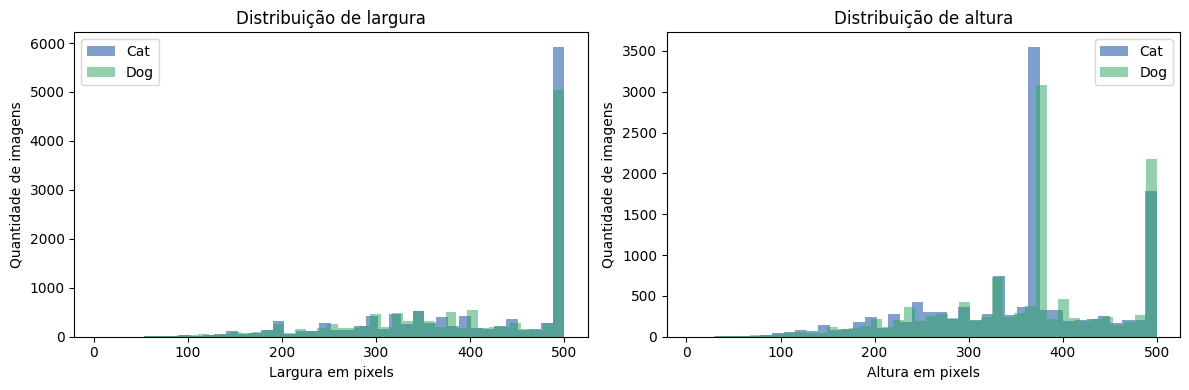

In [5]:
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import PurePosixPath
from PIL import Image, ImageFile
from tqdm.auto import tqdm
from IPython.display import display

# Não aceitar silenciosamente imagens truncadas.
ImageFile.LOAD_TRUNCATED_IMAGES = False

registros = []

with zipfile.ZipFile(arquivo_zip) as zip_ref:

    nomes = [
        nome for nome in zip_ref.namelist()
        if PurePosixPath(nome).parent.as_posix()
        in {"PetImages/Cat", "PetImages/Dog"}
        and PurePosixPath(nome).suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".gif",
            ".webp", ".tif", ".tiff"}
    ]

    for nome in tqdm(nomes, desc="Analisando imagens"):
        registro = {
            "arquivo": nome,
            "classe": PurePosixPath(nome).parent.name,
            "largura": None,
            "altura": None,
            "modo_cor": None,
            "status": "erro",
            "erro": ""
        }

        try:
            with zip_ref.open(nome) as arquivo:
                with Image.open(arquivo) as imagem:
                    imagem.load()  # Decodifica a imagem.
                    registro.update({
                        "largura": imagem.width,
                        "altura": imagem.height,
                        "modo_cor": imagem.mode,
                        "status": "ok"
                    })

        except Exception as erro:
            registro["erro"] = str(erro)

        registros.append(registro)

diagnostico = pd.DataFrame(registros)
validas = diagnostico[diagnostico["status"] == "ok"].copy()
falhas = diagnostico[diagnostico["status"] == "erro"].copy()

print("RESUMO POR CLASSE")
display(pd.crosstab(
    diagnostico["classe"],
    diagnostico["status"]
))

print("\nMODOS DE COR DAS IMAGENS LEGÍVEIS")
display(pd.crosstab(
    validas["classe"],
    validas["modo_cor"]
))

print("\nESTATÍSTICAS DAS DIMENSÕES — PIXELS")
display(
    validas[["largura", "altura"]]
    .astype(float)
    .describe()
    .round(1)
)

print(f"\nImagens com falha de leitura: {len(falhas)}")
display(falhas[["arquivo", "erro"]].head(20))

# Distribuições de largura e altura por classe.
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

for classe, cor in [("Cat", "#00429d"), ("Dog", "#2ca25f")]:
    dados = validas[validas["classe"] == classe]

    eixos[0].hist(
        dados["largura"].astype(float),
        bins=40, alpha=0.5, label=classe, color=cor
    )
    eixos[1].hist(
        dados["altura"].astype(float),
        bins=40, alpha=0.5, label=classe, color=cor
    )

for ax, dimensao in zip(eixos, ["Largura", "Altura"]):
    ax.set_title(f"Distribuição de {dimensao.lower()}")
    ax.set_xlabel(f"{dimensao} em pixels")
    ax.set_ylabel("Quantidade de imagens")
    ax.legend()

plt.tight_layout()
plt.show()

Imagens selecionadas para inspeção: 43


,arquivo,classe,largura,altura,modo_cor,proporcao_extrema
7694,PetImages/Cat/5673.jpg,Cat,4,4,RGB,1.000000
8505,PetImages/Cat/6402.jpg,Cat,60,33,RGB,1.818182
18743,PetImages/Dog/4367.jpg,Dog,196,33,P,5.939394
7540,PetImages/Cat/5534.jpg,Cat,60,36,RGB,1.666667
13890,PetImages/Dog/11248.jpg,Dog,100,37,RGB,2.702703
13333,PetImages/Dog/10747.jpg,Dog,50,39,P,1.282051
24674,PetImages/Dog/9705.jpg,Dog,60,39,RGB,1.538462
11581,PetImages/Cat/9171.jpg,Cat,145,39,P,3.717949
6748,PetImages/Cat/4821.jpg,Cat,60,40,RGB,1.500000
4095,PetImages/Cat/2433.jpg,Cat,60,41,RGB,1.463415



Quantidade por classe:
classe
Dog    26
Cat    17
Name: count, dtype: int64


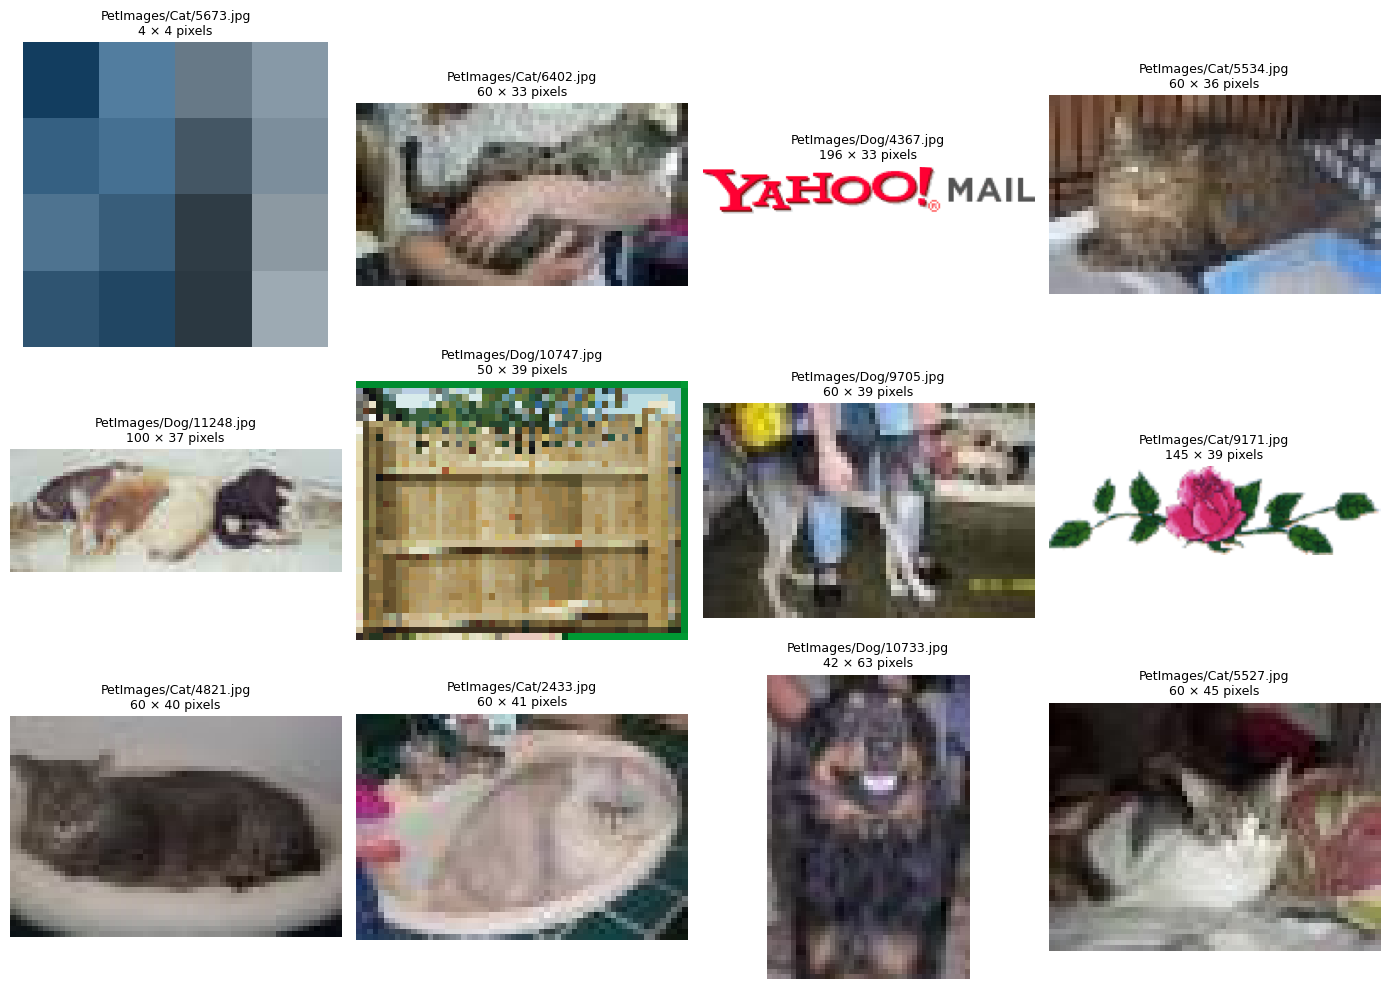

In [6]:
# Utiliza a tabela "validas" criada na análise anterior.
analise = validas.copy()

analise["largura"] = analise["largura"].astype(int)
analise["altura"] = analise["altura"].astype(int)

analise["menor_lado"] = analise[
    ["largura", "altura"]
].min(axis=1)

analise["maior_lado"] = analise[
    ["largura", "altura"]
].max(axis=1)

analise["proporcao_extrema"] = (
    analise["maior_lado"] / analise["menor_lado"]
)

# Critérios exploratórios para selecionar casos para inspeção.
# Não são regras automáticas de exclusão.
suspeitas = analise[
    (analise["menor_lado"] < 64)
    | (analise["proporcao_extrema"] > 4)
].sort_values(["menor_lado", "proporcao_extrema"])

print("Imagens selecionadas para inspeção:", len(suspeitas))

display(
    suspeitas[
        ["arquivo", "classe", "largura", "altura",
         "modo_cor", "proporcao_extrema"]
    ].head(30)
)

print("\nQuantidade por classe:")
print(suspeitas["classe"].value_counts())

# Exibir até 12 exemplos.
amostra = suspeitas.head(12)

if not amostra.empty:
    fig, eixos = plt.subplots(3, 4, figsize=(14, 10))

    for ax in eixos.flat:
        ax.axis("off")

    with zipfile.ZipFile(arquivo_zip) as zip_ref:
        for ax, (_, linha) in zip(eixos.flat, amostra.iterrows()):
            with zip_ref.open(linha["arquivo"]) as arquivo:
                with Image.open(arquivo) as imagem:
                    ax.imshow(imagem.convert("RGB"))

            ax.set_title(
                f"{linha['arquivo']}\n"
                f"{linha['largura']} × {linha['altura']} pixels",
                fontsize=9
            )

    plt.tight_layout()
    plt.show()
else:
    print("Nenhuma imagem atende aos critérios de inspeção.")

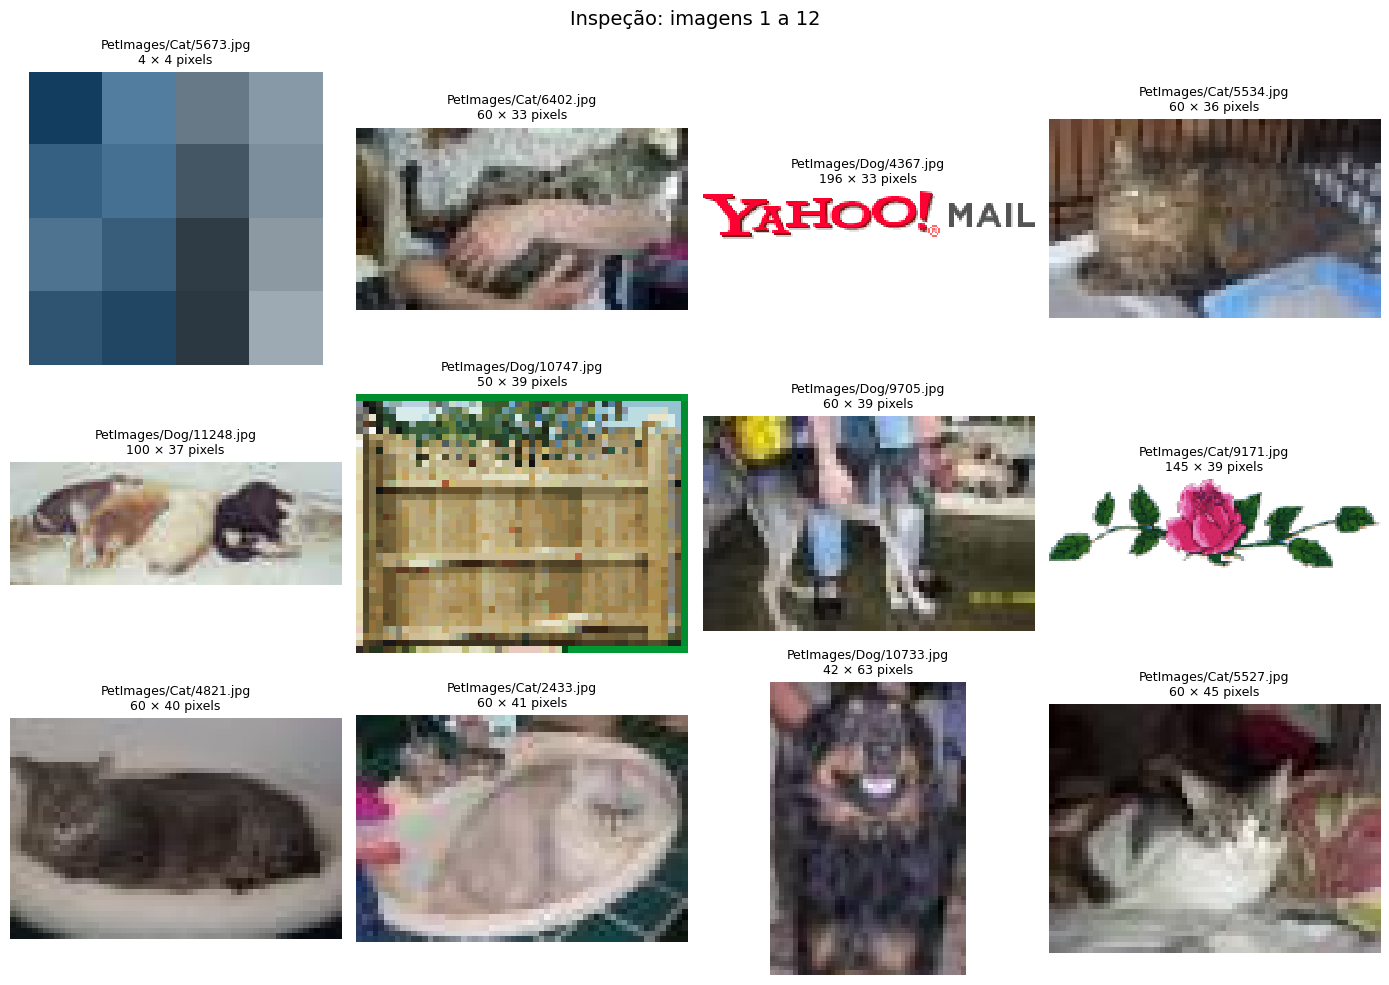

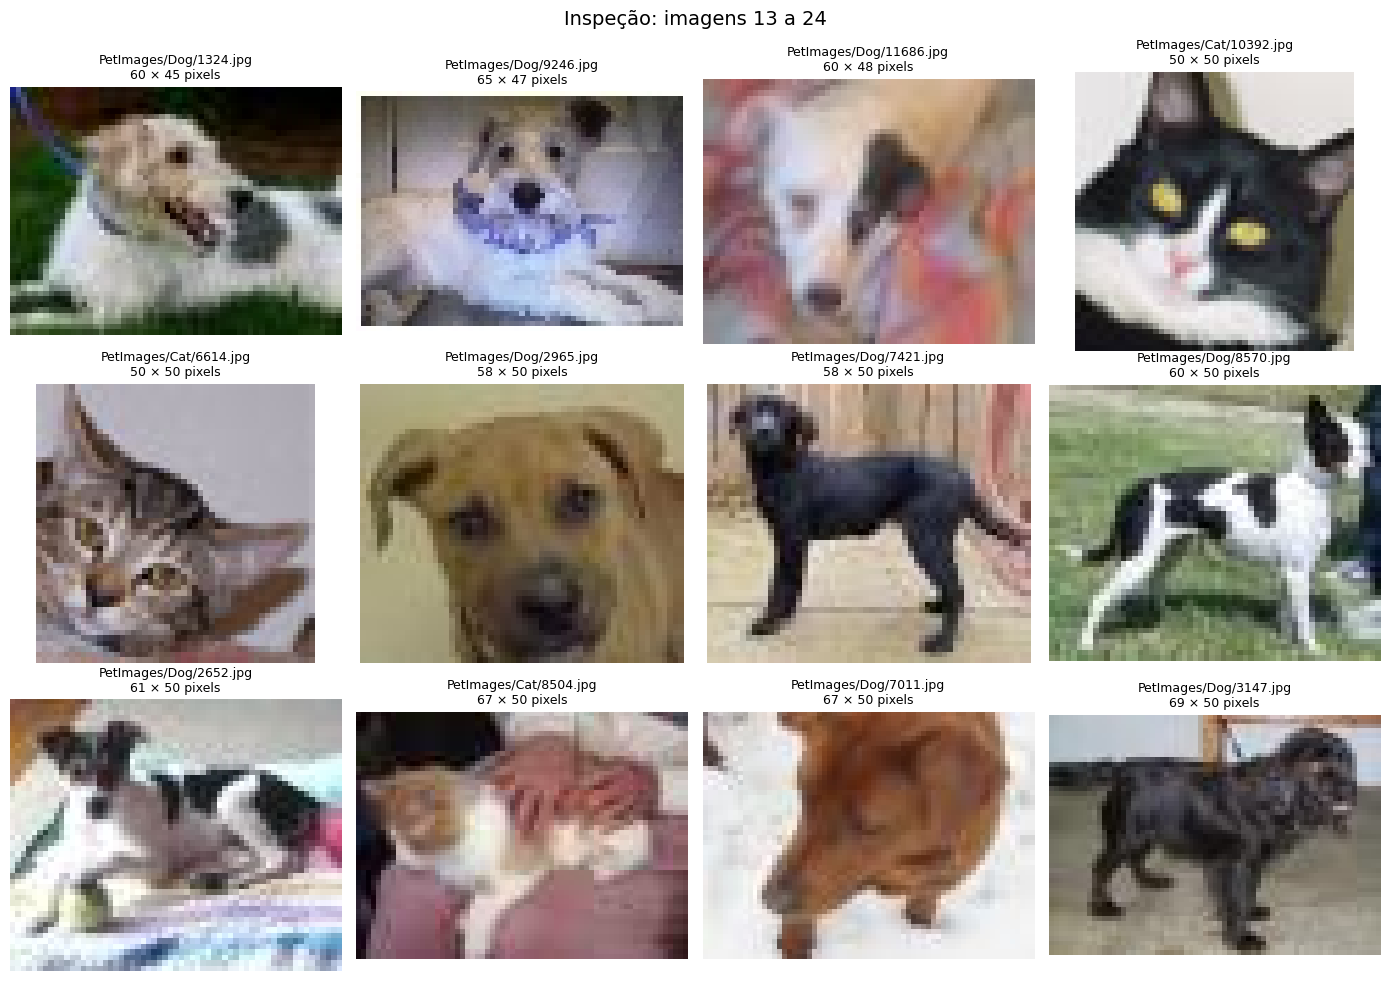

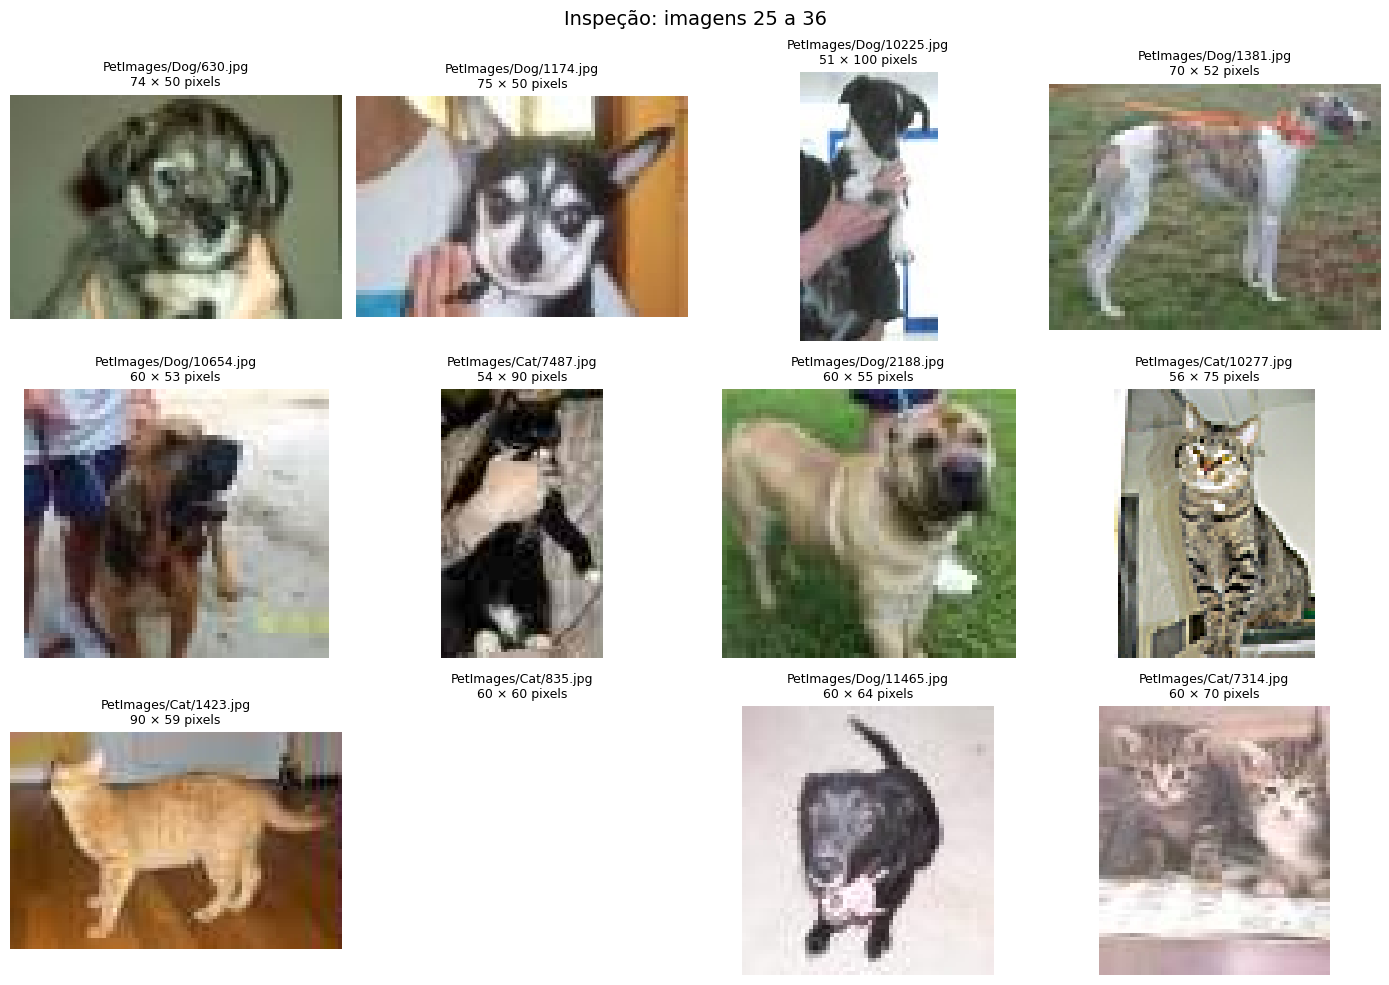

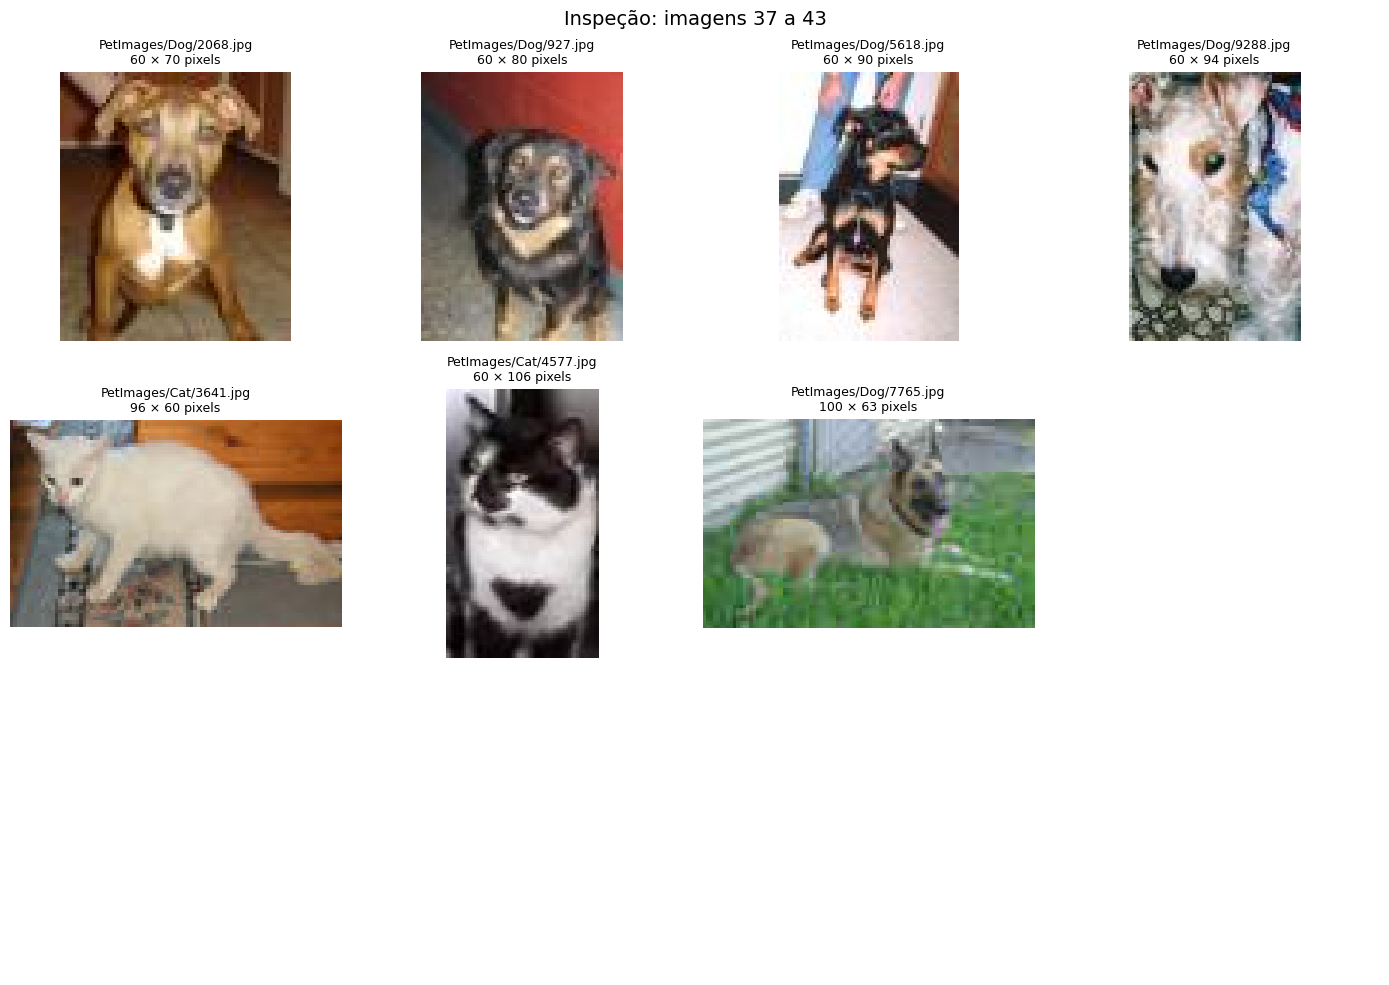

In [7]:
# Exibe todas as imagens selecionadas, em grupos de até 12.
with zipfile.ZipFile(arquivo_zip) as zip_ref:

    for inicio in range(0, len(suspeitas), 12):
        grupo = suspeitas.iloc[inicio:inicio + 12]

        fig, eixos = plt.subplots(3, 4, figsize=(14, 10))

        for ax in eixos.flat:
            ax.axis("off")

        for ax, (_, linha) in zip(eixos.flat, grupo.iterrows()):
            with zip_ref.open(linha["arquivo"]) as arquivo:
                with Image.open(arquivo) as imagem:
                    ax.imshow(
                        imagem.convert("RGB"),
                        interpolation="nearest"
                    )

            ax.set_title(
                f"{linha['arquivo']}\n"
                f"{linha['largura']} × {linha['altura']} pixels",
                fontsize=9
            )

        fig.suptitle(
            f"Inspeção: imagens {inicio + 1} "
            f"a {inicio + len(grupo)}",
            fontsize=14
        )
        plt.tight_layout()
        plt.show()

In [8]:
exclusoes_confirmadas = {
    "PetImages/Cat/666.jpg": "Falha de leitura",
    "PetImages/Dog/11702.jpg": "Falha de leitura",
    "PetImages/Cat/5673.jpg": "Resolução de apenas 4 × 4 pixels",
    "PetImages/Dog/4367.jpg": "Logotipo Yahoo! Mail",
    "PetImages/Cat/9171.jpg": "Imagem de uma rosa"
}

In [9]:
tabela_exclusoes = pd.DataFrame(
    exclusoes_confirmadas.items(),
    columns=["Arquivo", "Motivo"]
)

display(tabela_exclusoes)

,Arquivo,Motivo
0,PetImages/Cat/666.jpg,Falha de leitura
1,PetImages/Dog/11702.jpg,Falha de leitura
2,PetImages/Cat/5673.jpg,Resolução de apenas 4 × 4 pixels
3,PetImages/Dog/4367.jpg,Logotipo Yahoo! Mail
4,PetImages/Cat/9171.jpg,Imagem de uma rosa


Arquivo: PetImages/Cat/835.jpg
Dimensões: 60 × 60


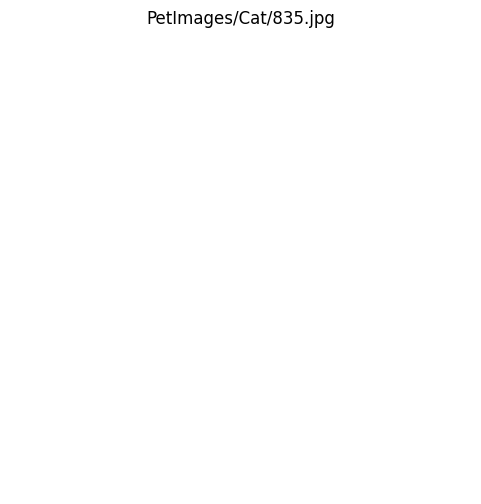

In [10]:
# Última linha, segunda coluna do painel 25 a 36
registro = suspeitas.iloc[33]

print("Arquivo:", registro["arquivo"])
print("Dimensões:", registro["largura"], "×", registro["altura"])

with zipfile.ZipFile(arquivo_zip) as zip_ref:
    with zip_ref.open(registro["arquivo"]) as arquivo:
        with Image.open(arquivo) as imagem:
            plt.figure(figsize=(6, 6))
            plt.imshow(imagem.convert("RGB"), interpolation="nearest")
            plt.title(registro["arquivo"])
            plt.axis("off")
            plt.show()

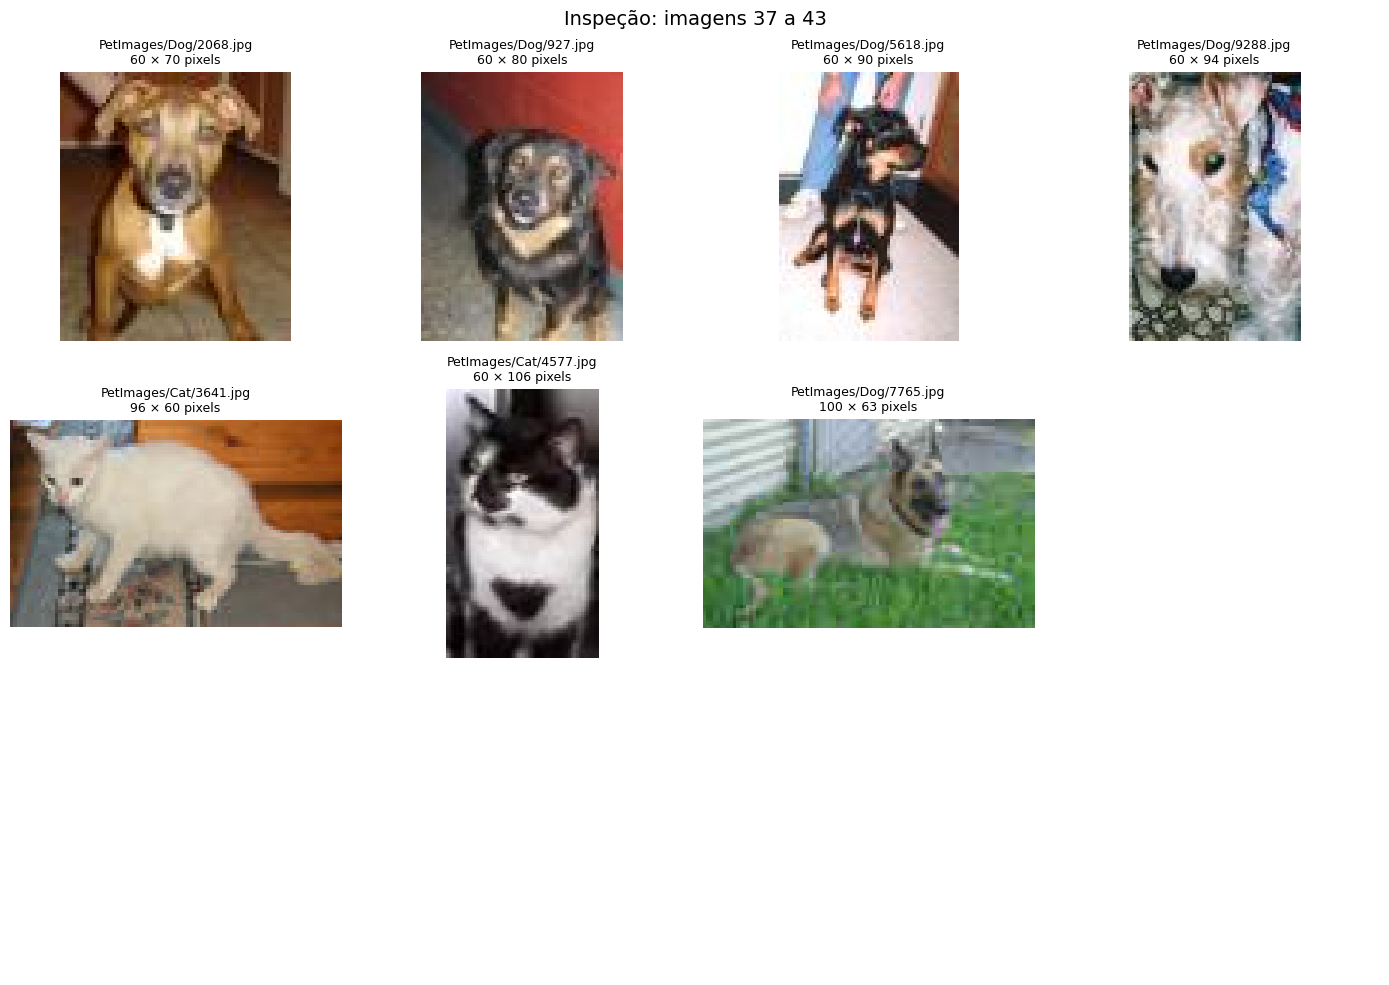

In [11]:
# Exibe todas as imagens selecionadas, em grupos de até 12.
with zipfile.ZipFile(arquivo_zip) as zip_ref:

    for inicio in[36]:
        grupo = suspeitas.iloc[inicio:inicio + 12]

        fig, eixos = plt.subplots(3, 4, figsize=(14, 10))

        for ax in eixos.flat:
            ax.axis("off")

        for ax, (_, linha) in zip(eixos.flat, grupo.iterrows()):
            with zip_ref.open(linha["arquivo"]) as arquivo:
                with Image.open(arquivo) as imagem:
                    ax.imshow(
                        imagem.convert("RGB"),
                        interpolation="nearest"
                    )

            ax.set_title(
                f"{linha['arquivo']}\n"
                f"{linha['largura']} × {linha['altura']} pixels",
                fontsize=9
            )

        fig.suptitle(
            f"Inspeção: imagens {inicio + 1} "
            f"a {inicio + len(grupo)}",
            fontsize=14
        )
        plt.tight_layout()
        plt.show()

In [12]:
import hashlib
from collections import defaultdict

grupos_hash = defaultdict(list)

with zipfile.ZipFile(arquivo_zip) as zip_ref:
    for nome in tqdm(validas["arquivo"], desc="Buscando duplicados"):
        with zip_ref.open(nome) as arquivo:
            hash_arquivo = hashlib.file_digest(
                arquivo, "sha256"
            ).hexdigest()

        grupos_hash[hash_arquivo].append(nome)

duplicados = [
    nomes for nomes in grupos_hash.values()
    if len(nomes) > 1
]

print("Grupos de arquivos idênticos:", len(duplicados))
print(
    "Cópias extras:",
    sum(len(grupo) - 1 for grupo in duplicados)
)

for numero, grupo in enumerate(duplicados[:20], start=1):
    print(f"\nGrupo {numero}:")
    for nome in grupo:
        print(" ", nome)

Buscando duplicados:   0%|          | 0/24998 [00:00<?, ?it/s]

Grupos de arquivos idênticos: 28
Cópias extras: 30

Grupo 1:
  PetImages/Cat/10052.jpg
  PetImages/Cat/1930.jpg

Grupo 2:
  PetImages/Cat/10273.jpg
  PetImages/Cat/1639.jpg

Grupo 3:
  PetImages/Cat/10360.jpg
  PetImages/Cat/3345.jpg

Grupo 4:
  PetImages/Cat/11053.jpg
  PetImages/Cat/4667.jpg

Grupo 5:
  PetImages/Cat/11197.jpg
  PetImages/Cat/3910.jpg

Grupo 6:
  PetImages/Cat/11565.jpg
  PetImages/Dog/10401.jpg
  PetImages/Dog/10797.jpg
  PetImages/Dog/2877.jpg

Grupo 7:
  PetImages/Cat/11595.jpg
  PetImages/Cat/8137.jpg

Grupo 8:
  PetImages/Cat/11706.jpg
  PetImages/Cat/11974.jpg

Grupo 9:
  PetImages/Cat/12408.jpg
  PetImages/Cat/2339.jpg

Grupo 10:
  PetImages/Cat/2580.jpg
  PetImages/Cat/4726.jpg

Grupo 11:
  PetImages/Cat/3112.jpg
  PetImages/Cat/7545.jpg

Grupo 12:
  PetImages/Cat/3411.jpg
  PetImages/Cat/4435.jpg

Grupo 13:
  PetImages/Cat/3908.jpg
  PetImages/Cat/7912.jpg

Grupo 14:
  PetImages/Cat/4126.jpg
  PetImages/Cat/4575.jpg

Grupo 15:
  PetImages/Cat/4442.jpg
  PetI

Grupos com conflito de classe: 2

CONFLITO 1
  PetImages/Cat/11565.jpg
  PetImages/Dog/10401.jpg
  PetImages/Dog/10797.jpg
  PetImages/Dog/2877.jpg


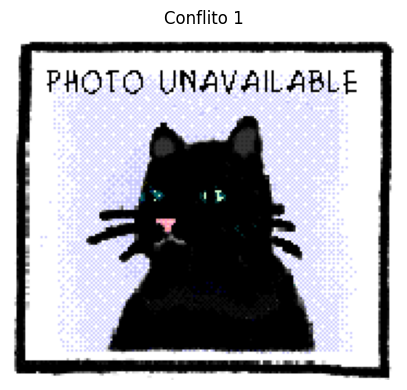


CONFLITO 2
  PetImages/Cat/8456.jpg
  PetImages/Dog/8736.jpg


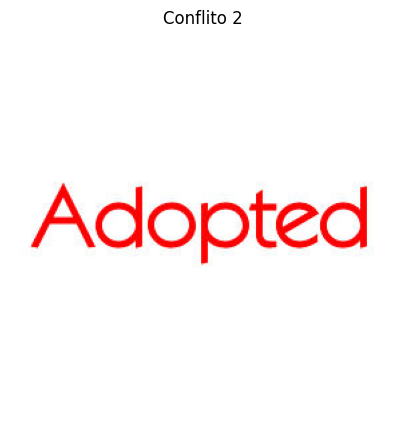

In [13]:
from pathlib import PurePosixPath

# Seleciona grupos com arquivos presentes em classes diferentes.
conflitos = [
    grupo for grupo in duplicados
    if len({
        PurePosixPath(nome).parent.name
        for nome in grupo
    }) > 1
]

print("Grupos com conflito de classe:", len(conflitos))

with zipfile.ZipFile(arquivo_zip) as zip_ref:
    for numero, grupo in enumerate(conflitos, start=1):
        print(f"\nCONFLITO {numero}")
        for nome in grupo:
            print(" ", nome)

        # Basta abrir uma cópia: os arquivos são idênticos.
        with zip_ref.open(grupo[0]) as arquivo:
            with Image.open(arquivo) as imagem:
                plt.figure(figsize=(5, 5))
                plt.imshow(imagem.convert("RGB"))
                plt.title(f"Conflito {numero}")
                plt.axis("off")
                plt.show()

In [14]:
novas_exclusoes = {
    "PetImages/Cat/11565.jpg": "Imagem substituta: PHOTO UNAVAILABLE",
    "PetImages/Dog/10401.jpg": "Imagem substituta: PHOTO UNAVAILABLE",
    "PetImages/Dog/10797.jpg": "Imagem substituta: PHOTO UNAVAILABLE",
    "PetImages/Dog/2877.jpg": "Imagem substituta: PHOTO UNAVAILABLE",
    "PetImages/Cat/8456.jpg": "Imagem substituta: texto Adopted",
    "PetImages/Dog/8736.jpg": "Imagem substituta: texto Adopted"
}

exclusoes_confirmadas.update(novas_exclusoes)

display(pd.DataFrame(
    exclusoes_confirmadas.items(),
    columns=["Arquivo", "Motivo"]
))

print("Total de exclusões registradas:", len(exclusoes_confirmadas))

,Arquivo,Motivo
0,PetImages/Cat/666.jpg,Falha de leitura
1,PetImages/Dog/11702.jpg,Falha de leitura
2,PetImages/Cat/5673.jpg,Resolução de apenas 4 × 4 pixels
3,PetImages/Dog/4367.jpg,Logotipo Yahoo! Mail
4,PetImages/Cat/9171.jpg,Imagem de uma rosa
5,PetImages/Cat/11565.jpg,Imagem substituta: PHOTO UNAVAILABLE
6,PetImages/Dog/10401.jpg,Imagem substituta: PHOTO UNAVAILABLE
7,PetImages/Dog/10797.jpg,Imagem substituta: PHOTO UNAVAILABLE
8,PetImages/Dog/2877.jpg,Imagem substituta: PHOTO UNAVAILABLE
9,PetImages/Cat/8456.jpg,Imagem substituta: texto Adopted


Total de exclusões registradas: 11


In [15]:
# Imagens que ainda precisam de revisão visual.
pendentes = {
    "PetImages/Cat/835.jpg",
    "PetImages/Dog/10747.jpg"
}

# Começa pelas imagens legíveis, sem as exclusões confirmadas.
candidatas = validas[
    ~validas["arquivo"].isin(exclusoes_confirmadas)
].copy()

# Seleciona uma cópia por grupo de arquivos idênticos.
# A ordenação torna a escolha reproduzível.
nomes_candidatos = set(candidatas["arquivo"])
copias_extras = set()

for grupo in duplicados:
    restantes = sorted(
        nome for nome in grupo
        if nome in nomes_candidatos
    )
    copias_extras.update(restantes[1:])

# Lista após retirar as repetições.
sem_duplicatas = candidatas[
    ~candidatas["arquivo"].isin(copias_extras)
].copy()

# Separa os casos pendentes.
base_provisoria = sem_duplicatas[
    ~sem_duplicatas["arquivo"].isin(pendentes)
].copy()

print("Imagens legíveis:", len(validas))
print("Após exclusões confirmadas:", len(candidatas))
print("Cópias extras retiradas da lista:", len(copias_extras))
print("Após retirar duplicatas:", len(sem_duplicatas))
print("Base provisória, sem pendentes:", len(base_provisoria))

print("\nQUANTIDADE POR CLASSE")
display(
    base_provisoria.groupby("classe")
    .size()
    .rename("Quantidade")
    .to_frame()
)

Imagens legíveis: 24998
Após exclusões confirmadas: 24989
Cópias extras retiradas da lista: 26
Após retirar duplicatas: 24963
Base provisória, sem pendentes: 24961

QUANTIDADE POR CLASSE


,Quantidade
classe,
Cat,12477
Dog,12484


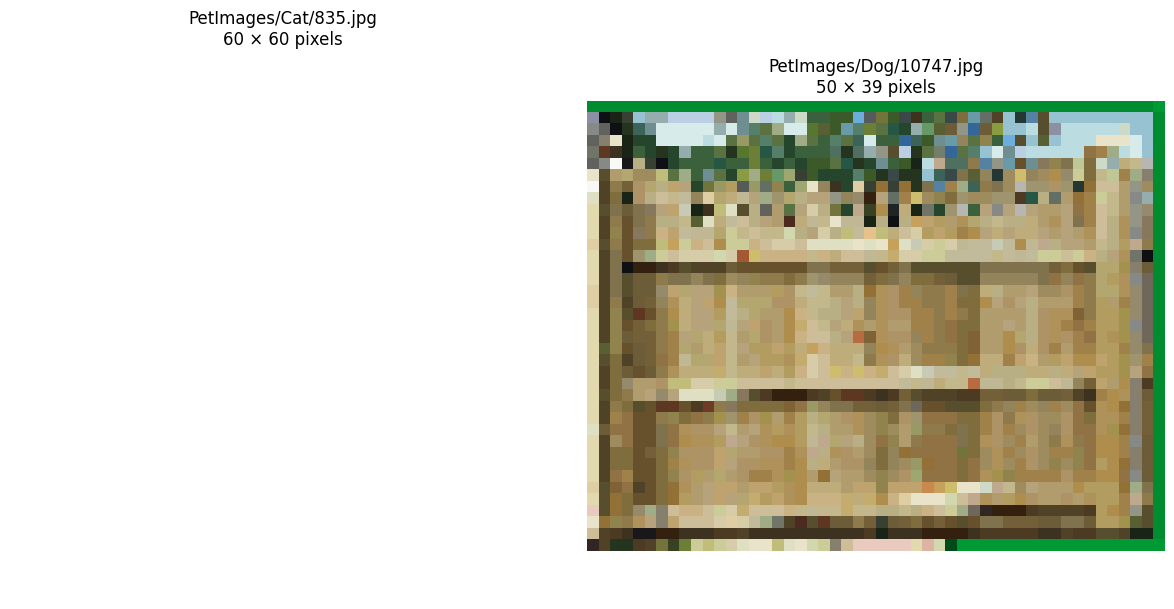

In [16]:
import zipfile
import matplotlib.pyplot as plt
from PIL import Image

arquivos_pendentes = [
    "PetImages/Cat/835.jpg",
    "PetImages/Dog/10747.jpg"
]

fig, eixos = plt.subplots(1, 2, figsize=(12, 6))

with zipfile.ZipFile(arquivo_zip) as zip_ref:
    for ax, nome in zip(eixos, arquivos_pendentes):
        with zip_ref.open(nome) as arquivo:
            with Image.open(arquivo) as imagem:
                imagem.load()
                largura, altura = imagem.size

                ax.imshow(
                    imagem.convert("RGB"),
                    interpolation="nearest"
                )

        ax.set_title(f"{nome}\n{largura} × {altura} pixels")
        ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
exclusoes_confirmadas.update({
    "PetImages/Cat/835.jpg":
        "Imagem aparentemente branca, sem animal visível",
    "PetImages/Dog/10747.jpg":
        "Animal não reconhecível na inspeção visual"
})

# Recria a base a partir das imagens legíveis,
# retirando exclusões e cópias extras já identificadas.
base_provisoria = validas[
    ~validas["arquivo"].isin(exclusoes_confirmadas)
    & ~validas["arquivo"].isin(copias_extras)
].copy()

pendentes = set()

print("Exclusões por leitura ou conteúdo:",
      len(exclusoes_confirmadas))
print("Imagens na base provisória:", len(base_provisoria))

display(
    base_provisoria.groupby("classe")
    .size()
    .rename("Quantidade")
    .to_frame()
)

Exclusões por leitura ou conteúdo: 13
Imagens na base provisória: 24961


,Quantidade
classe,
Cat,12477
Dog,12484


Calculando resumos visuais:   0%|          | 0/24961 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Comparando resumos:   0%|          | 0/24961 [00:00<?, ?it/s]


Pares candidatos: 6
Falhas nesta análise: 0


,Imagem A,Imagem B,Distância pHash,Classes diferentes
0,PetImages/Cat/2565.jpg,PetImages/Cat/3565.jpg,0,False
1,PetImages/Cat/4852.jpg,PetImages/Cat/6442.jpg,0,False
2,PetImages/Dog/5163.jpg,PetImages/Dog/6026.jpg,0,False
3,PetImages/Dog/5733.jpg,PetImages/Dog/9746.jpg,0,False
4,PetImages/Dog/6357.jpg,PetImages/Dog/9603.jpg,0,False
5,PetImages/Dog/6421.jpg,PetImages/Dog/6902.jpg,0,False


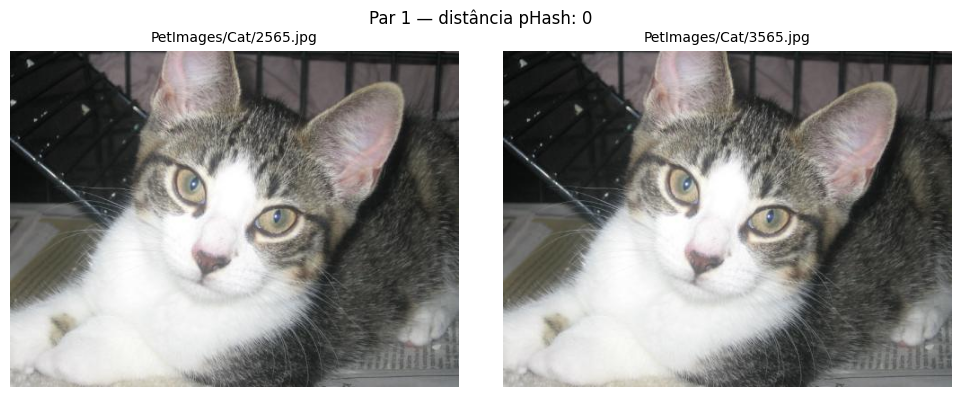

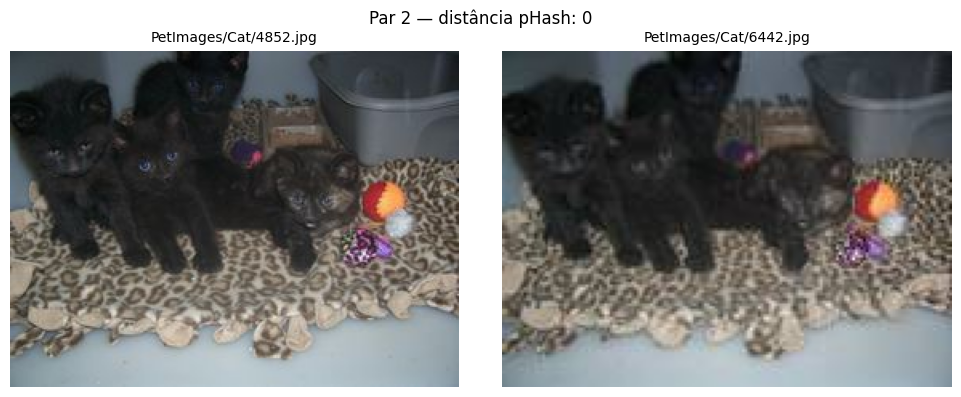

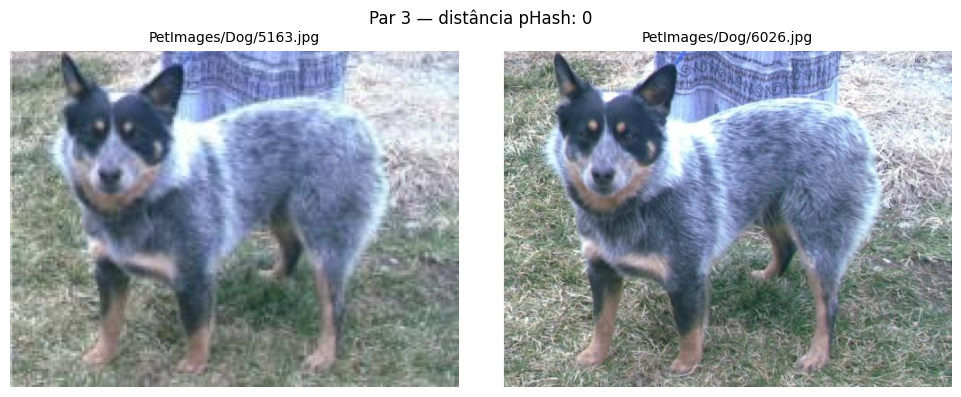

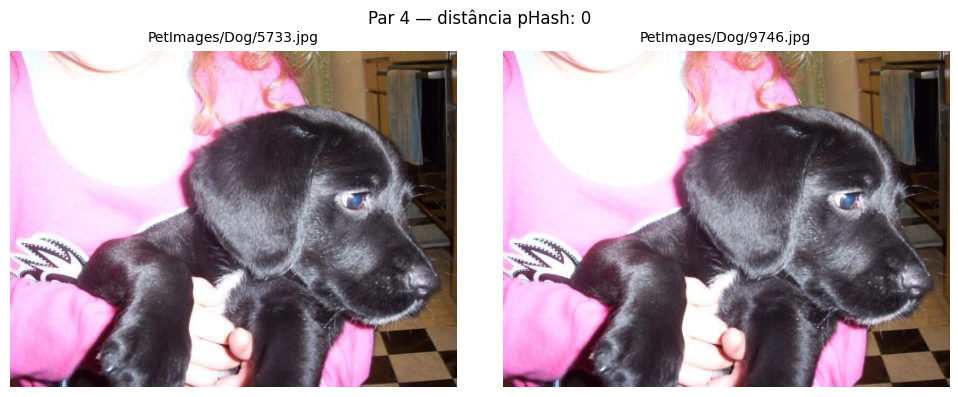

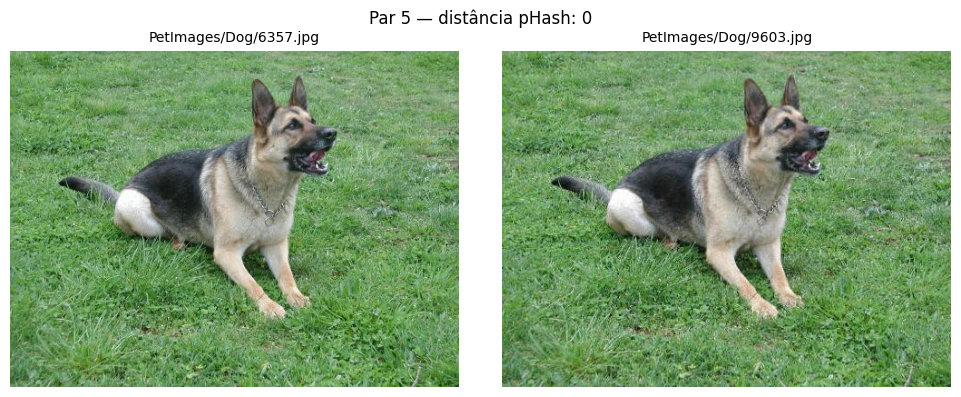

In [18]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from scipy.fft import dctn
from tqdm.auto import tqdm
from IPython.display import display

# ======================================================
# 1. CALCULAR UM RESUMO VISUAL DE 64 BITS POR IMAGEM
# ======================================================
def calcular_phash(imagem):
    imagem = ImageOps.exif_transpose(imagem)
    cinza = imagem.convert("L").resize(
        (32, 32), Image.Resampling.LANCZOS
    )

    matriz = np.asarray(cinza, dtype=float)
    frequencias = dctn(matriz, type=2, norm="ortho")[:8, :8]

    # A primeira frequência representa principalmente o brilho.
    mediana = np.median(frequencias.flatten()[1:])
    bits = (frequencias > mediana).flatten()
    bits[0] = False

    valor = 0
    for bit in bits:
        valor = (valor << 1) | int(bit)

    return valor


hashes_visuais = []
falhas_phash = []

with zipfile.ZipFile(arquivo_zip) as zip_ref:
    for nome in tqdm(
        base_provisoria["arquivo"],
        desc="Calculando resumos visuais"
    ):
        try:
            with zip_ref.open(nome) as arquivo:
                with Image.open(arquivo) as imagem:
                    imagem.load()
                    resumo = calcular_phash(imagem)

            hashes_visuais.append((nome, resumo))

        except Exception as erro:
            falhas_phash.append((nome, str(erro)))

# ======================================================
# 2. BUSCAR HASHES PRÓXIMOS COM UMA ÁRVORE DE DISTÂNCIAS
# ======================================================
def distancia(a, b):
    # Quantidade de bits diferentes.
    return (a ^ b).bit_count()


arvore = None

def inserir(valor, indice):
    global arvore

    if arvore is None:
        arvore = [valor, [indice], {}]
        return

    no = arvore

    while True:
        d = distancia(valor, no[0])

        if d == 0:
            no[1].append(indice)
            return

        if d not in no[2]:
            no[2][d] = [valor, [indice], {}]
            return

        no = no[2][d]


def buscar(valor, limite):
    encontrados = []
    pilha = [] if arvore is None else [arvore]

    while pilha:
        no = pilha.pop()
        d = distancia(valor, no[0])

        if d <= limite:
            encontrados.extend((indice, d) for indice in no[1])

        for aresta, filho in no[2].items():
            if d - limite <= aresta <= d + limite:
                pilha.append(filho)

    return encontrados


# Critério exploratório: até 4 bits diferentes em 64.
# Menor distância significa hashes mais próximos.
limite = 4
pares = []

for indice, (nome, resumo) in enumerate(
    tqdm(hashes_visuais, desc="Comparando resumos")
):
    for anterior, d in buscar(resumo, limite):
        outro_nome = hashes_visuais[anterior][0]

        pares.append({
            "Imagem A": outro_nome,
            "Imagem B": nome,
            "Distância pHash": d,
            "Classes diferentes":
                outro_nome.split("/")[-2] != nome.split("/")[-2]
        })

    inserir(resumo, indice)

pares_semelhantes = pd.DataFrame(
    pares,
    columns=[
        "Imagem A", "Imagem B",
        "Distância pHash", "Classes diferentes"
    ]
).sort_values(
    ["Distância pHash", "Imagem A", "Imagem B"]
).reset_index(drop=True)

print("\nPares candidatos:", len(pares_semelhantes))
print("Falhas nesta análise:", len(falhas_phash))
display(pares_semelhantes.head(20))

# ======================================================
# 3. MOSTRAR OS PRIMEIROS CINCO PARES PARA REVISÃO
# ======================================================
with zipfile.ZipFile(arquivo_zip) as zip_ref:
    for numero, linha in pares_semelhantes.head(5).iterrows():
        fig, eixos = plt.subplots(1, 2, figsize=(10, 4))

        for ax, coluna in zip(eixos, ["Imagem A", "Imagem B"]):
            nome = linha[coluna]

            with zip_ref.open(nome) as arquivo:
                with Image.open(arquivo) as imagem:
                    visual = ImageOps.exif_transpose(imagem)
                    ax.imshow(visual.convert("RGB"))

            ax.set_title(nome, fontsize=10)
            ax.axis("off")

        fig.suptitle(
            f"Par {numero + 1} — "
            f"distância pHash: {linha['Distância pHash']}"
        )
        plt.tight_layout()
        plt.show()

if pares_semelhantes.empty:
    print("Nenhum par encontrado com esse limite.")

In [19]:
# Registra os cinco pares que acabamos de revisar.
pares_confirmados = pares_semelhantes.head(5).copy()

print("Pares confirmados visualmente:", len(pares_confirmados))
print("Total de pares candidatos:", len(pares_semelhantes))
print("Falhas na análise:", len(falhas_phash))

display(pares_confirmados)

Pares confirmados visualmente: 5
Total de pares candidatos: 6
Falhas na análise: 0


,Imagem A,Imagem B,Distância pHash,Classes diferentes
0,PetImages/Cat/2565.jpg,PetImages/Cat/3565.jpg,0,False
1,PetImages/Cat/4852.jpg,PetImages/Cat/6442.jpg,0,False
2,PetImages/Dog/5163.jpg,PetImages/Dog/6026.jpg,0,False
3,PetImages/Dog/5733.jpg,PetImages/Dog/9746.jpg,0,False
4,PetImages/Dog/6357.jpg,PetImages/Dog/9603.jpg,0,False


Distância pHash: 0
Classes diferentes: False


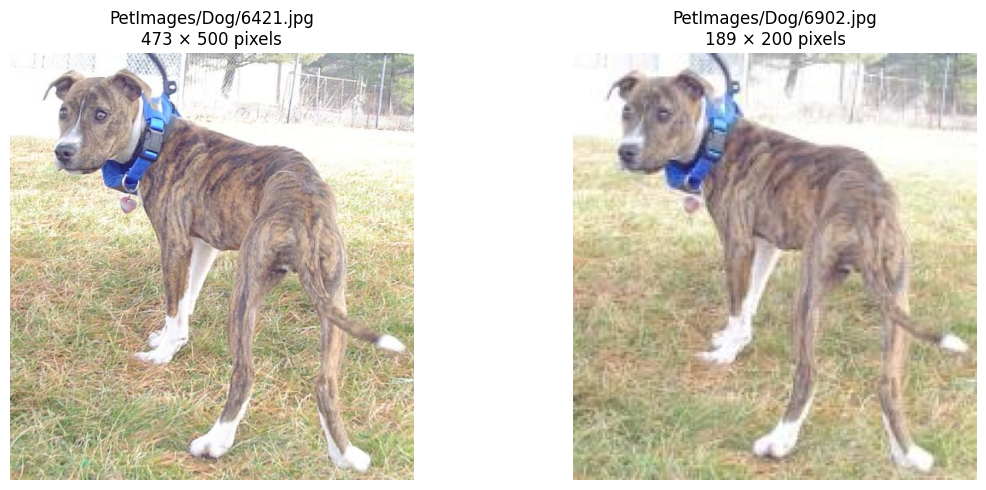

In [20]:
# Mostra o sexto e último par candidato.
par = pares_semelhantes.iloc[5]

print("Distância pHash:", par["Distância pHash"])
print("Classes diferentes:", par["Classes diferentes"])

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

with zipfile.ZipFile(arquivo_zip) as zip_ref:
    for ax, coluna in zip(eixos, ["Imagem A", "Imagem B"]):
        nome = par[coluna]

        with zip_ref.open(nome) as arquivo:
            with Image.open(arquivo) as imagem:
                visual = ImageOps.exif_transpose(imagem)
                largura, altura = visual.size
                ax.imshow(visual.convert("RGB"))

        ax.set_title(f"{nome}\n{largura} × {altura} pixels")
        ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
# Os seis pares foram revisados visualmente.
pares_confirmados = pares_semelhantes.copy()

dimensoes = validas.set_index("arquivo")
duplicatas_visuais = set()
decisoes = []

for _, par in pares_confirmados.iterrows():
    nomes = [par["Imagem A"], par["Imagem B"]]

    # Maior resolução primeiro; nome como desempate.
    nomes = sorted(
        nomes,
        key=lambda nome: (
            -int(dimensoes.loc[nome, "largura"])
            * int(dimensoes.loc[nome, "altura"]),
            nome
        )
    )

    manter, retirar = nomes
    duplicatas_visuais.add(retirar)

    decisoes.append({
        "Manter": manter,
        "Retirar da lista": retirar
    })

# Usa a base atual sem alterar os arquivos originais.
base_revisada = base_provisoria[
    ~base_provisoria["arquivo"].isin(duplicatas_visuais)
].copy()

display(pd.DataFrame(decisoes))

print("Duplicatas visuais retiradas:", len(duplicatas_visuais))
print("Imagens na base revisada:", len(base_revisada))

display(
    base_revisada.groupby("classe")
    .size()
    .rename("Quantidade")
    .to_frame()
)

,Manter,Retirar da lista
0,PetImages/Cat/2565.jpg,PetImages/Cat/3565.jpg
1,PetImages/Cat/4852.jpg,PetImages/Cat/6442.jpg
2,PetImages/Dog/6026.jpg,PetImages/Dog/5163.jpg
3,PetImages/Dog/5733.jpg,PetImages/Dog/9746.jpg
4,PetImages/Dog/6357.jpg,PetImages/Dog/9603.jpg
5,PetImages/Dog/6421.jpg,PetImages/Dog/6902.jpg


Duplicatas visuais retiradas: 6
Imagens na base revisada: 24955


,Quantidade
classe,
Cat,12475
Dog,12480


In [22]:
resumo = base_revisada.groupby("classe").size().to_frame("Quantidade")
resumo.loc["TOTAL"] = resumo["Quantidade"].sum()

display(resumo)

,Quantidade
classe,
Cat,12475
Dog,12480
TOTAL,24955


In [23]:
import io
from PIL import Image, ImageOps

TAM = 128
N_POR_CLASSE = 3000          # None para usar a base inteira
destino = Path("/content/dataset")

amostra = (base_revisada.groupby("classe", group_keys=False)
           .apply(lambda g: g.sample(n=min(N_POR_CLASSE, len(g)), random_state=42))
           if N_POR_CLASSE else base_revisada)

with zipfile.ZipFile(arquivo_zip) as zip_ref:
    for _, linha in tqdm(amostra.iterrows(), total=len(amostra)):
        pasta_destino = destino / linha["classe"]
        pasta_destino.mkdir(parents=True, exist_ok=True)
        with zip_ref.open(linha["arquivo"]) as f:
            img = Image.open(io.BytesIO(f.read()))
            img = ImageOps.exif_transpose(img).convert("RGB").resize((TAM, TAM))
            img.save(pasta_destino / PurePosixPath(linha["arquivo"]).name, "JPEG", quality=90)

/tmp/ipykernel_669/4231060717.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(N_POR_CLASSE, len(g)), random_state=42))


  0%|          | 0/6000 [00:00<?, ?it/s]

In [24]:
from sklearn.model_selection import train_test_split

amostra["caminho"] = amostra.apply(
    lambda r: str(destino / r["classe"] / PurePosixPath(r["arquivo"]).name), axis=1)
amostra["rotulo"] = (amostra["classe"] == "Dog").astype(int)

treino, temp = train_test_split(amostra, test_size=0.30, stratify=amostra["rotulo"], random_state=42)
valid, teste = train_test_split(temp, test_size=0.50, stratify=temp["rotulo"], random_state=42)

for nome, df in [("treino", treino), ("validacao", valid), ("teste", teste)]:
    df.to_csv(pasta / f"split_{nome}.csv", index=False)
    print(nome, len(df), df["rotulo"].value_counts().to_dict())

treino 4200 {1: 2100, 0: 2100}
validacao 900 {0: 450, 1: 450}
teste 900 {1: 450, 0: 450}


In [28]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import MobileNetV2

def construir_modelo_tl(lr, dropout, otimizador, camadas_treinaveis, unidades=128):
    base = MobileNetV2(input_shape=(TAM, TAM, 3), include_top=False, weights="imagenet")
    base.trainable = False
    if camadas_treinaveis > 0:
        for camada in base.layers[-camadas_treinaveis:]:
            # BatchNorm permanece congelada: destrava-la com poucos dados desestabiliza o treino
            if not isinstance(camada, layers.BatchNormalization):
                camada.trainable = True

    entrada = layers.Input((TAM, TAM, 3))
    # criar_datasets entrega pixels em [0,1]; a MobileNetV2 espera [-1,1].
    # (Para ResNet50 troque por: layers.Lambda(lambda x: tf.keras.applications.resnet50.preprocess_input(x*255)))
    x = layers.Rescaling(2.0, offset=-1.0)(entrada)
    x = base(x, training=False)          # mantém as estatísticas da BatchNorm do ImageNet
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(unidades, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    saida = layers.Dense(1, activation="sigmoid")(x)
    m = models.Model(entrada, saida)

    opt = {"adam": optimizers.Adam(lr),
           "sgd": optimizers.SGD(lr, momentum=0.9),
           "rmsprop": optimizers.RMSprop(lr)}[otimizador]
    m.compile(opt, loss="binary_crossentropy", metrics=["accuracy"])
    return m

# Desafio — Otimização de uma CNN com Grid Search (Cats vs Dogs)

Adaptação do notebook `CNN_Cats_vs_Dogs.ipynb` (PyTorch) às exigências do desafio:

1. **Divisão fixa 70 / 15 / 15** (treino / validação / teste), estratificada e com semente.
2. **Grid Search** sobre learning rate, batch size, filtros/camadas convolucionais, dropout e otimizador.
3. Seleção do melhor modelo usando **apenas treino + validação**; o conjunto de teste só aparece na avaliação final.
4. Comparação de **loss + acurácia** nos três conjuntos, **curvas de aprendizado** do melhor modelo.
5. Seção extra: o mesmo protocolo aplicado a **transfer learning (ResNet18)**, para comparar as duas abordagens.

Correções em relação ao código original: a perda passa a ser `CrossEntropyLoss` sobre logits (o `NLLLoss`
padrão do skorch sobre logits gerava perdas negativas e `nan`); o subconjunto do grid era só de gatos
(`range(1000)` em um `ImageFolder` ordenado); augmentation só no treino; backbone da ResNet congelado de fato.

> Ambiente recomendado: Google Colab com **GPU T4** (*Ambiente de execução → Alterar o tipo de ambiente de execução*).

## 1. Setup

In [30]:
!pip -q install kagglehub

import os, io, time, random, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ATENÇÃO: sem GPU o grid completo leva horas. Ative a GPU T4 no Colab.")

Dispositivo: cpu
ATENÇÃO: sem GPU o grid completo leva horas. Ative a GPU T4 no Colab.


## 2. Dataset e divisão fixa 70 / 15 / 15

O dataset do Kaggle vem pré-dividido em `training_set` (8 000) e `test_set` (2 000). Como o desafio pede uma
divisão **própria** de 70/15/15, as duas pastas são reunidas em um único conjunto de 10 000 imagens e
divididas de forma estratificada com semente fixa. A divisão é salva em CSV para ser reproduzível.

Para usar outro dataset (por exemplo a base Microsoft `PetImages` já curada), basta apontar `PASTAS_CLASSES`
para as pastas de cada classe.

In [31]:
import kagglehub

path = Path(kagglehub.dataset_download("jakupymeraj/cats-and-dogs-image-dataset"))
raiz = path / "dataset"

# Reúne training_set + test_set em um único conjunto; o split é feito por nós.
PASTAS_CLASSES = {
    "cat": [raiz / "training_set" / "cats", raiz / "test_set" / "cats"],
    "dog": [raiz / "training_set" / "dogs", raiz / "test_set" / "dogs"],
}
CLASSES = list(PASTAS_CLASSES.keys())

registros = []
for rotulo, classe in enumerate(CLASSES):
    for pasta in PASTAS_CLASSES[classe]:
        for arq in sorted(pasta.glob("*")):
            if arq.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                registros.append({"caminho": str(arq), "classe": classe, "rotulo": rotulo})

base = pd.DataFrame(registros)
print("Total de imagens:", len(base))
display(base["classe"].value_counts())

treino, temp = train_test_split(base, test_size=0.30, stratify=base["rotulo"], random_state=SEED)
valid, teste = train_test_split(temp, test_size=0.50, stratify=temp["rotulo"], random_state=SEED)

for nome, df in [("treino", treino), ("validacao", valid), ("teste", teste)]:
    df.to_csv(f"split_{nome}.csv", index=False)
    print(f"{nome:10s} {len(df):5d}  {df['classe'].value_counts().to_dict()}")

Using Colab cache for faster access to the 'cats-and-dogs-image-dataset' dataset.
Total de imagens: 10000


,count
classe,
cat,5000
dog,5000


treino      7000  {'dog': 3500, 'cat': 3500}
validacao   1500  {'dog': 750, 'cat': 750}
teste       1500  {'cat': 750, 'dog': 750}


### Carregamento em memória
As imagens são redimensionadas uma única vez para `IMG × IMG` e mantidas em RAM como tensores `uint8`
(10 000 × 3 × 128 × 128 ≈ 490 MB). Isso elimina o gargalo de leitura de disco e torna cada combinação do grid
muito mais rápida. Augmentation (flip + rotação leve) **só no treino**; validação e teste recebem apenas a normalização.

  0%|          | 0/7000 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

torch.Size([7000, 3, 128, 128]) torch.Size([1500, 3, 128, 128]) torch.Size([1500, 3, 128, 128])


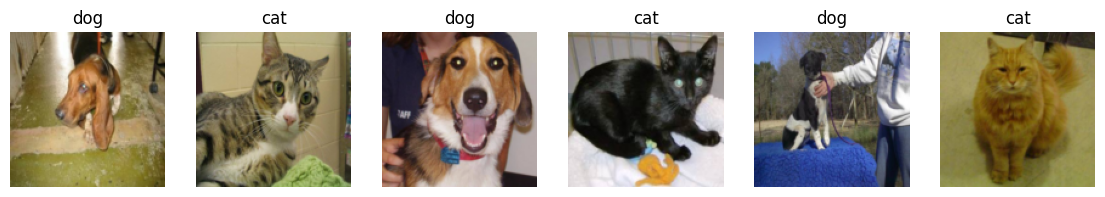

In [32]:
IMG = 128   # 160 ou 224 melhoram a ResNet18, ao custo de tempo

def carregar_tensores(df):
    arr = np.empty((len(df), 3, IMG, IMG), dtype=np.uint8)
    for i, caminho in enumerate(tqdm(df["caminho"].values, leave=False)):
        with Image.open(caminho) as im:
            im = im.convert("RGB").resize((IMG, IMG), Image.BILINEAR)
            arr[i] = np.asarray(im).transpose(2, 0, 1)
    return torch.from_numpy(arr), torch.tensor(df["rotulo"].values, dtype=torch.long)

X_tr, y_tr = carregar_tensores(treino)
X_va, y_va = carregar_tensores(valid)
X_te, y_te = carregar_tensores(teste)
print(X_tr.shape, X_va.shape, X_te.shape)

MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
DESVIO = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

aug_treino = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
])

class ImagensEmMemoria(Dataset):
    def __init__(self, X, y, augment=False):
        self.X, self.y, self.augment = X, y, augment
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = self.X[i]
        if self.augment:
            x = aug_treino(x)
        x = x.float() / 255.0
        x = (x - MEDIA[0]) / DESVIO[0]
        return x, self.y[i]

def criar_loaders(batch_size):
    ds_tr = ImagensEmMemoria(X_tr, y_tr, augment=True)
    ds_va = ImagensEmMemoria(X_va, y_va)
    ds_te = ImagensEmMemoria(X_te, y_te)
    kw = dict(num_workers=2, pin_memory=(device.type == "cuda"))
    return (DataLoader(ds_tr, batch_size=batch_size, shuffle=True, **kw),
            DataLoader(ds_va, batch_size=batch_size, shuffle=False, **kw),
            DataLoader(ds_te, batch_size=batch_size, shuffle=False, **kw))

# Amostra visual
fig, eixos = plt.subplots(1, 6, figsize=(14, 3))
for ax, i in zip(eixos, np.random.choice(len(X_tr), 6, replace=False)):
    ax.imshow(X_tr[i].permute(1, 2, 0).numpy()); ax.set_title(CLASSES[y_tr[i]]); ax.axis("off")
plt.show()

## 3. CNN parametrizável

A `SimpleCNN` original tinha filtros fixos (16 → 32 → 64), 3 blocos, sem dropout e uma camada `Linear(64·28·28, 512)`
com 25 milhões de parâmetros. Aqui a arquitetura recebe os hiperparâmetros do grid: número de filtros iniciais
(dobrando a cada bloco), número de blocos convolucionais e dropout. `AdaptiveAvgPool2d` substitui o `Flatten`
gigante e torna a rede independente do tamanho da imagem.

In [33]:
class CNN(nn.Module):
    def __init__(self, filtros=32, n_blocos=3, dropout=0.5, n_classes=2):
        super().__init__()
        camadas, entrada, f = [], 3, filtros
        for _ in range(n_blocos):
            camadas += [nn.Conv2d(entrada, f, 3, padding=1), nn.BatchNorm2d(f), nn.ReLU(inplace=True),
                        nn.MaxPool2d(2)]
            entrada, f = f, f * 2
        self.conv = nn.Sequential(*camadas)
        self.cabeca = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(entrada, 128), nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, n_classes),
        )
    def forward(self, x):
        return self.cabeca(self.conv(x))

m = CNN(32, 3, 0.5)
print(m)
print("Parâmetros:", sum(p.numel() for p in m.parameters()))

CNN(
  (conv): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (cabeca): Sequential(
    (0): AdaptiveAvgPool2d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=12

## 4. Rotinas de treino e avaliação

In [34]:
def criar_otimizador(nome, parametros, lr):
    if nome == "adam":
        return optim.Adam(parametros, lr=lr)
    if nome == "sgd":
        return optim.SGD(parametros, lr=lr, momentum=0.9)
    if nome == "rmsprop":
        return optim.RMSprop(parametros, lr=lr)
    raise ValueError(nome)

criterio = nn.CrossEntropyLoss()   # sobre logits — correção do NLLLoss do original

@torch.no_grad()
def avaliar(modelo, loader):
    modelo.eval()
    perda_total, acertos, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        saida = modelo(x)
        perda_total += criterio(saida, y).item() * len(y)
        acertos += (saida.argmax(1) == y).sum().item()
        n += len(y)
    return perda_total / n, acertos / n

def treinar(modelo, otimizador, loader_tr, loader_va, epocas=10, paciencia=3, verbose=False):
    """Treina com early stopping em val_loss e devolve (histórico, melhores pesos, melhor época)."""
    modelo.to(device)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    melhor_val, melhor_estado, melhor_ep, sem_melhora = float("inf"), None, 0, 0
    for ep in range(epocas):
        modelo.train()
        perda_total, acertos, n = 0.0, 0, 0
        for x, y in loader_tr:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            otimizador.zero_grad(set_to_none=True)
            saida = modelo(x)
            perda = criterio(saida, y)
            perda.backward()
            otimizador.step()
            perda_total += perda.item() * len(y)
            acertos += (saida.argmax(1) == y).sum().item()
            n += len(y)
        vl, va = avaliar(modelo, loader_va)
        hist["train_loss"].append(perda_total / n); hist["train_acc"].append(acertos / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if verbose:
            print(f"  época {ep+1:2d}  train_loss={perda_total/n:.4f} acc={acertos/n:.4f} | "
                  f"val_loss={vl:.4f} acc={va:.4f}")
        if vl < melhor_val - 1e-4:
            melhor_val, melhor_ep, sem_melhora = vl, ep, 0
            melhor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
    modelo.load_state_dict(melhor_estado)
    return hist, melhor_estado, melhor_ep

def plotar_curvas(hist, titulo):
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
    ep = range(1, len(hist["train_loss"]) + 1)
    eixos[0].plot(ep, hist["train_loss"], "o-", label="treino"); eixos[0].plot(ep, hist["val_loss"], "s-", label="validação")
    eixos[0].set_title("Loss"); eixos[0].set_xlabel("época"); eixos[0].legend()
    eixos[1].plot(ep, hist["train_acc"], "o-", label="treino"); eixos[1].plot(ep, hist["val_acc"], "s-", label="validação")
    eixos[1].set_title("Acurácia"); eixos[1].set_xlabel("época"); eixos[1].legend()
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

## 5. Grid Search da CNN — apenas treino + validação

O `GridSearchCV` + skorch do original é substituído por um laço explícito com `ParameterGrid`: fica transparente
que o teste **não** participa, e o histórico de cada combinação fica disponível para as curvas. Cada combinação
registra loss/acurácia de treino e validação na melhor época e o **gap** treino − validação (sinal de overfitting).
Os resultados são gravados em CSV a cada iteração.

Com 2 valores por hiperparâmetro são 32 combinações (≈ 1–2 min cada na T4). Reduza a grade para um teste rápido.

In [ ]:
grade_cnn = ParameterGrid({
    "lr":         [1e-3, 1e-4],
    "batch_size": [32, 64],
    "filtros":    [16, 32],
    "n_blocos":   [3, 4],
    "dropout":    [0.3, 0.5],
    "otimizador": ["adam", "sgd"],
})
EPOCAS_GRID = 10
print("Combinações:", len(grade_cnn))

resultados_cnn, historicos_cnn = [], {}
for i, cfg in enumerate(grade_cnn):
    torch.manual_seed(SEED)
    loader_tr, loader_va, _ = criar_loaders(cfg["batch_size"])
    modelo = CNN(cfg["filtros"], cfg["n_blocos"], cfg["dropout"])
    otimizador = criar_otimizador(cfg["otimizador"], modelo.parameters(), cfg["lr"])
    t0 = time.time()
    hist, _, ep = treinar(modelo, otimizador, loader_tr, loader_va, epocas=EPOCAS_GRID)
    resultados_cnn.append({**cfg, "epoca_melhor": ep + 1,
                           "train_loss": hist["train_loss"][ep], "train_acc": hist["train_acc"][ep],
                           "val_loss": hist["val_loss"][ep],     "val_acc": hist["val_acc"][ep],
                           "gap_acc": hist["train_acc"][ep] - hist["val_acc"][ep],
                           "tempo_s": round(time.time() - t0, 1)})
    historicos_cnn[i] = hist
    pd.DataFrame(resultados_cnn).to_csv("grid_cnn.csv", index=False)
    r = resultados_cnn[-1]
    print(f"[{i+1:2d}/{len(grade_cnn)}] val_loss={r['val_loss']:.4f} val_acc={r['val_acc']:.4f} "
          f"gap={r['gap_acc']:+.3f} ({r['tempo_s']:.0f}s) {cfg}")
    del modelo, otimizador; torch.cuda.empty_cache()

Combinações: 64


## 6. Seleção do melhor modelo (critério: generalização)

O ranking é por **menor `val_loss`**, e não por maior acurácia de treino. A coluna `gap_acc` mostra quanto o
modelo perde ao sair do treino: duas configurações com `val_acc` parecida podem ter gaps muito diferentes.
Os gráficos seguintes mostram o efeito isolado de cada hiperparâmetro (média da `val_acc` por valor).

In [ ]:
tabela_cnn = pd.DataFrame(resultados_cnn).sort_values("val_loss").reset_index(drop=True)
display(tabela_cnn.head(10).style.format({c: "{:.4f}" for c in
        ["train_loss", "train_acc", "val_loss", "val_acc", "gap_acc"]}))

melhor_cnn = tabela_cnn.iloc[0]
idx_melhor_cnn = int(pd.DataFrame(resultados_cnn).sort_values("val_loss").index[0])
print("\nMelhor combinação (CNN):")
print(melhor_cnn[["lr", "batch_size", "filtros", "n_blocos", "dropout", "otimizador"]].to_dict())

hiper = ["lr", "batch_size", "filtros", "n_blocos", "dropout", "otimizador"]
fig, eixos = plt.subplots(1, len(hiper), figsize=(18, 3.5))
for ax, h in zip(eixos, hiper):
    tabela_cnn.groupby(h)["val_acc"].mean().plot.bar(ax=ax, color="#4c72b0")
    ax.set_title(f"val_acc média por {h}"); ax.set_xlabel(""); ax.set_ylim(0.5, 1.0)
plt.tight_layout(); plt.show()

## 7. Retreino do melhor modelo e avaliação em treino / validação / teste

O conjunto de **teste** é usado aqui pela primeira vez.

In [ ]:
cfg = melhor_cnn
torch.manual_seed(SEED)
loader_tr, loader_va, loader_te = criar_loaders(int(cfg["batch_size"]))
modelo_cnn = CNN(int(cfg["filtros"]), int(cfg["n_blocos"]), float(cfg["dropout"]))
otimizador = criar_otimizador(cfg["otimizador"], modelo_cnn.parameters(), float(cfg["lr"]))
hist_cnn, _, ep = treinar(modelo_cnn, otimizador, loader_tr, loader_va, epocas=20, paciencia=4, verbose=True)
torch.save(modelo_cnn.state_dict(), "melhor_cnn.pt")

# avaliação do treino sem augmentation, para comparação justa
loader_tr_eval = DataLoader(ImagensEmMemoria(X_tr, y_tr), batch_size=128)
desempenho_cnn = pd.DataFrame(
    [avaliar(modelo_cnn, l) for l in (loader_tr_eval, loader_va, loader_te)],
    columns=["loss", "acurácia"], index=["treino", "validação", "teste"])
display(desempenho_cnn.style.format("{:.4f}"))

plotar_curvas(hist_cnn, f"CNN — melhor configuração (melhor época: {ep+1})")

modelo_cnn.eval(); preds = []
with torch.no_grad():
    for x, _ in loader_te:
        preds.append(modelo_cnn(x.to(device)).argmax(1).cpu())
ConfusionMatrixDisplay(confusion_matrix(y_te, torch.cat(preds)), display_labels=CLASSES).plot(cmap="Blues")
plt.title("CNN — matriz de confusão (teste)"); plt.show()

## 8. Transfer learning (ResNet18) com o mesmo protocolo

No original, a ResNet18 foi treinada com hiperparâmetros fixos e avaliada diretamente no teste. Aqui ela passa pelo
**mesmo Grid Search em treino + validação**. O backbone é congelado de fato (`requires_grad=False`) e mantido em
`eval()` para preservar as estatísticas de BatchNorm do ImageNet; o hiperparâmetro `descongelar_layer4` substitui
"número de camadas" — permite fine-tuning do último bloco residual.

In [ ]:
class ResNet18TL(nn.Module):
    def __init__(self, dropout=0.5, descongelar_layer4=False, n_classes=2):
        super().__init__()
        base = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        for p in base.parameters():
            p.requires_grad = False
        if descongelar_layer4:
            for p in base.layer4.parameters():
                p.requires_grad = True
        n_feat = base.fc.in_features
        base.fc = nn.Identity()
        self.base, self.descongelar = base, descongelar_layer4
        self.cabeca = nn.Sequential(nn.Dropout(dropout), nn.Linear(n_feat, n_classes))
    def train(self, mode=True):
        super().train(mode)
        self.base.eval()                      # BatchNorm do backbone sempre em modo de inferência
        if self.descongelar and mode:
            self.base.layer4.train()
        return self
    def forward(self, x):
        return self.cabeca(self.base(x))
    def parametros_treinaveis(self):
        return [p for p in self.parameters() if p.requires_grad]

grade_tl = ParameterGrid({
    "lr":                 [1e-3, 1e-4],
    "batch_size":         [32, 64],
    "dropout":            [0.3, 0.5],
    "otimizador":         ["adam", "sgd"],
    "descongelar_layer4": [False, True],
})
print("Combinações:", len(grade_tl))

resultados_tl, historicos_tl = [], {}
for i, cfg in enumerate(grade_tl):
    torch.manual_seed(SEED)
    loader_tr, loader_va, _ = criar_loaders(cfg["batch_size"])
    modelo = ResNet18TL(cfg["dropout"], cfg["descongelar_layer4"])
    otimizador = criar_otimizador(cfg["otimizador"], modelo.parametros_treinaveis(), cfg["lr"])
    t0 = time.time()
    hist, _, ep = treinar(modelo, otimizador, loader_tr, loader_va, epocas=6, paciencia=2)
    resultados_tl.append({**cfg, "epoca_melhor": ep + 1,
                          "train_loss": hist["train_loss"][ep], "train_acc": hist["train_acc"][ep],
                          "val_loss": hist["val_loss"][ep],     "val_acc": hist["val_acc"][ep],
                          "gap_acc": hist["train_acc"][ep] - hist["val_acc"][ep],
                          "tempo_s": round(time.time() - t0, 1)})
    historicos_tl[i] = hist
    pd.DataFrame(resultados_tl).to_csv("grid_tl.csv", index=False)
    r = resultados_tl[-1]
    print(f"[{i+1:2d}/{len(grade_tl)}] val_loss={r['val_loss']:.4f} val_acc={r['val_acc']:.4f} "
          f"gap={r['gap_acc']:+.3f} ({r['tempo_s']:.0f}s) {cfg}")
    del modelo, otimizador; torch.cuda.empty_cache()

tabela_tl = pd.DataFrame(resultados_tl).sort_values("val_loss").reset_index(drop=True)
display(tabela_tl.head(10).style.format({c: "{:.4f}" for c in
        ["train_loss", "train_acc", "val_loss", "val_acc", "gap_acc"]}))
melhor_tl = tabela_tl.iloc[0]
print("\nMelhor combinação (ResNet18):", melhor_tl[["lr", "batch_size", "dropout", "otimizador", "descongelar_layer4"]].to_dict())

In [ ]:
cfg = melhor_tl
torch.manual_seed(SEED)
loader_tr, loader_va, loader_te = criar_loaders(int(cfg["batch_size"]))
modelo_tl = ResNet18TL(float(cfg["dropout"]), bool(cfg["descongelar_layer4"]))
otimizador = criar_otimizador(cfg["otimizador"], modelo_tl.parametros_treinaveis(), float(cfg["lr"]))
hist_tl, _, ep = treinar(modelo_tl, otimizador, loader_tr, loader_va, epocas=10, paciencia=3, verbose=True)
torch.save(modelo_tl.state_dict(), "melhor_resnet18.pt")

desempenho_tl = pd.DataFrame(
    [avaliar(modelo_tl, l) for l in (loader_tr_eval, loader_va, loader_te)],
    columns=["loss", "acurácia"], index=["treino", "validação", "teste"])
display(desempenho_tl.style.format("{:.4f}"))
plotar_curvas(hist_tl, f"ResNet18 — melhor configuração (melhor época: {ep+1})")

modelo_tl.eval(); preds = []
with torch.no_grad():
    for x, _ in loader_te:
        preds.append(modelo_tl(x.to(device)).argmax(1).cpu())
ConfusionMatrixDisplay(confusion_matrix(y_te, torch.cat(preds)), display_labels=CLASSES).plot(cmap="Oranges")
plt.title("ResNet18 — matriz de confusão (teste)"); plt.show()

## 9. Comparação final — CNN do zero × Transfer learning

In [ ]:
comparacao = pd.concat({"CNN (do zero)": desempenho_cnn, "ResNet18 (transfer)": desempenho_tl}, axis=1)
display(comparacao.style.format("{:.4f}"))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(eixos, ["loss", "acurácia"]):
    pd.DataFrame({"CNN (do zero)": desempenho_cnn[metrica],
                  "ResNet18 (transfer)": desempenho_tl[metrica]}).plot.bar(ax=ax, rot=0,
                  color=["#4c72b0", "#dd8452"])
    ax.set_title(f"{metrica} por conjunto")
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.show()

print("Melhores hiperparâmetros — CNN:     ", melhor_cnn[["lr", "batch_size", "filtros", "n_blocos", "dropout", "otimizador"]].to_dict())
print("Melhores hiperparâmetros — ResNet18:", melhor_tl[["lr", "batch_size", "dropout", "otimizador", "descongelar_layer4"]].to_dict())

## 10. Conclusões (preencher após a execução)

- **Melhor combinação de hiperparâmetros** da CNN e da ResNet18 (tabelas das seções 6 e 8).
- **Loss e acurácia em treino, validação e teste** (seção 9): o teste confirma, ou não, o que a validação indicou?
- **Curvas de aprendizado** (seções 7 e 8): onde o gap treino–validação começa a abrir?
- Qual hiperparâmetro mais influenciou a generalização (gráficos da seção 6)?
- Por que a configuração com maior acurácia de **treino** não é necessariamente a escolhida?